# Four-building annual data preparation

This notebook processes the raw 15-minute data into **full-year hourly energy profiles for four buildings in 2023**.

Each output CSV:

- uses `timestamp` as the hourly index;
- contains `load_kwh`, `pv_kwh`, and `outdoor_temperature_c`;
- contains all 8,760 consecutive hours of 2023;
- includes only lighting and electric-equipment loads, with HVAC fully excluded;
- multiplies the PV profile by the building-specific weight defined in `PV_SCALING_WEIGHTS` before export;
- uses the same hourly outdoor-temperature series for all four buildings.

Each 15-minute power value is first converted to interval energy (`W × 0.25 h / 1000`), and the four intervals within each hour are then summed. PV `generation(kWh)` is summed hourly and subsequently scaled. Minute-level outdoor temperature is averaged hourly; missing full hours are filled from the mean of the same hour one week before and after.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

TARGET_YEAR = 2023
DATA_DIR = Path("building data")
OUTPUT_DIR = Path("data")
TEMPERATURE_FILE = DATA_DIR / "Temperature_2023.csv"

# Edit these four weights to scale each building's raw PV profile.
PV_SCALING_WEIGHTS = {
    "Residential 1": 0.5,
    "Residential 2": 0.5,
    "Large Commercial 1": 1.0,
    "Large Commercial 2": 0.25,
}

EXPECTED_INDEX = pd.date_range(
    f"{TARGET_YEAR}-01-01 00:00:00",
    f"{TARGET_YEAR}-12-31 23:00:00",
    freq="h",
    name="timestamp",
)

plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
LOAD_COLUMN_MARKERS = (
    "Lights Electricity Rate [W]",
    "Electric Equipment Electricity Rate [W]",
)


def expected_hour_index(year):
    return pd.date_range(
        f"{year}-01-01 00:00:00",
        f"{year}-12-31 23:00:00",
        freq="h",
        name="timestamp",
    )


def energyplus_interval_starts(values, year):
    """Convert EnergyPlus interval-end labels to 15-minute start timestamps."""
    text = values.astype(str).str.strip()
    parts = text.str.extract(
        r"(?P<month>\d{2})/(?P<day>\d{2})\s+"
        r"(?P<hour>\d{2}):(?P<minute>\d{2}):(?P<second>\d{2})$"
    )
    if parts.isna().any().any():
        bad = text.loc[parts.isna().any(axis=1)].head().tolist()
        raise ValueError(f"Cannot parse EnergyPlus timestamps: {bad}")

    calendar_day = pd.to_datetime(
        {
            "year": pd.Series(year, index=parts.index),
            "month": parts["month"].astype(int),
            "day": parts["day"].astype(int),
        }
    )
    end_minutes = parts["hour"].astype(int) * 60 + parts["minute"].astype(int)
    interval_starts = (
        calendar_day
        + pd.to_timedelta(end_minutes, unit="m")
        + pd.to_timedelta(parts["second"].astype(int), unit="s")
        - pd.Timedelta(minutes=15)
    )
    interval_starts.name = "timestamp"
    return interval_starts


def require_four_intervals_per_hour(hour_index, source_name, year):
    expected = expected_hour_index(year)
    counts = hour_index.value_counts().sort_index().reindex(expected, fill_value=0)
    invalid = counts[counts != 4]
    if not invalid.empty:
        sample = {str(key): int(value) for key, value in invalid.head().items()}
        raise ValueError(
            f"{source_name} must contain four 15-minute records per hour; "
            f"invalid sample: {sample}"
        )


def prepare_hourly_load(path, year):
    """Extract non-HVAC load and aggregate 15-minute rates to hourly kWh."""
    raw = pd.read_csv(path)
    raw.columns = raw.columns.str.strip()
    source_time = raw.iloc[:, 0]
    timestamps = energyplus_interval_starts(source_time, year)

    load_columns = [
        column
        for column in raw.columns
        if any(marker in column for marker in LOAD_COLUMN_MARKERS)
    ]
    if not load_columns:
        raise ValueError(f"No lights/electric-equipment columns found in {path.name}")

    power_w = raw[load_columns].apply(pd.to_numeric, errors="raise").sum(axis=1)
    interval_kwh = power_w * 0.25 / 1000.0
    hour_index = timestamps.dt.floor("h")
    require_four_intervals_per_hour(hour_index, path.name, year)

    hourly = interval_kwh.groupby(hour_index).sum().reindex(expected_hour_index(year))
    hourly.name = "load_kwh"
    return hourly


def prepare_hourly_pv(path, year):
    """Select one complete PV year and sum interval generation to hourly kWh."""
    raw = pd.read_csv(path)
    raw.columns = raw.columns.str.strip()
    required = {"Time", "generation(kWh)"}
    missing = required.difference(raw.columns)
    if missing:
        raise ValueError(f"{path.name} is missing columns: {sorted(missing)}")

    timestamps = pd.to_datetime(raw["Time"], errors="coerce")
    if timestamps.isna().any():
        raise ValueError(f"{path.name} contains invalid timestamps")

    selected = raw.loc[timestamps.dt.year == year].copy()
    selected_time = timestamps.loc[selected.index]
    if selected.empty:
        raise ValueError(f"{path.name} has no data for {year}")

    hour_index = selected_time.dt.floor("h")
    require_four_intervals_per_hour(hour_index, path.name, year)
    interval_kwh = pd.to_numeric(selected["generation(kWh)"], errors="raise")
    hourly = interval_kwh.groupby(hour_index).sum().reindex(expected_hour_index(year))
    hourly.name = "pv_kwh"
    return hourly


def prepare_hourly_temperature(path, year):
    """Average minute-level temperature hourly and fill missing full hours."""
    raw = pd.read_csv(path)
    raw.columns = raw.columns.str.strip()
    required = {"Time", "Temp (Degree Celsius)"}
    missing = required.difference(raw.columns)
    if missing:
        raise ValueError(f"{path.name} is missing columns: {sorted(missing)}")

    timestamps = pd.to_datetime(raw["Time"], errors="coerce")
    if timestamps.isna().any():
        raise ValueError(f"{path.name} contains invalid timestamps")
    if timestamps.duplicated().any():
        raise ValueError(f"{path.name} contains duplicate timestamps")

    selected = raw.loc[timestamps.dt.year == year, "Temp (Degree Celsius)"]
    selected_time = timestamps.loc[selected.index]
    temperature = pd.Series(
        pd.to_numeric(selected, errors="raise").to_numpy(),
        index=selected_time,
    )
    hourly = temperature.resample("h").mean().reindex(expected_hour_index(year))
    missing_hours = int(hourly.isna().sum())

    # Preserve the diurnal pattern across gaps by using the same hour in the
    # preceding and following weeks, then use time interpolation as a fallback.
    weekly_estimate = (hourly.shift(24 * 7) + hourly.shift(-24 * 7)) / 2.0
    hourly = hourly.fillna(weekly_estimate)
    hourly = hourly.interpolate(method="time").ffill().bfill()
    if hourly.isna().any():
        raise ValueError(f"Unable to fill all missing temperatures in {path.name}")

    hourly.name = "outdoor_temperature_c"
    print(f"Prepared outdoor temperature: filled {missing_hours} missing full hours")
    return hourly


def validate_profile(profile, name, year):
    """Enforce the output contract used by buildings.py."""
    expected = expected_hour_index(year)
    expected_columns = ["load_kwh", "pv_kwh", "outdoor_temperature_c"]
    if list(profile.columns) != expected_columns:
        raise ValueError(f"{name}: unexpected columns {profile.columns.tolist()}")
    if not profile.index.equals(expected):
        raise ValueError(f"{name}: timestamps are not a complete hourly year")
    if profile.isna().any().any():
        raise ValueError(f"{name}: profile contains missing values")
    if (profile[["load_kwh", "pv_kwh"]] < -1e-9).any().any():
        raise ValueError(f"{name}: profile contains negative energy")
    if len(profile) != len(expected):
        raise ValueError(f"{name}: expected {len(expected)} rows, got {len(profile)}")


def build_annual_profile(
    load_path,
    pv_path,
    hourly_temperature,
    year,
    pv_scaling_weight=1.0,
):
    if pv_scaling_weight < 0:
        raise ValueError("pv_scaling_weight must be non-negative")

    load = prepare_hourly_load(load_path, year)
    pv = prepare_hourly_pv(pv_path, year) * pv_scaling_weight
    profile = pd.concat([load, pv, hourly_temperature], axis=1)
    profile.index.name = "timestamp"
    profile[["load_kwh", "pv_kwh"]] = profile[["load_kwh", "pv_kwh"]].clip(
        lower=0.0
    )
    return profile

## Building/source mapping

The two residential buildings and two large commercial buildings each use an independent full-year output file. The configuration below is the single mapping point between the raw load and PV sources.

In [3]:
BUILDING_CONFIGS = {
    "Residential 1": {
        "load_file": DATA_DIR / "6zone_Residential House.csv",
        "pv_file": DATA_DIR / "SQ1.csv",
        "output_file": OUTPUT_DIR / "residential_1_2023.csv",
    },
    "Residential 2": {
        "load_file": DATA_DIR / "6zone_Residential House_C_1_new.csv",
        "pv_file": DATA_DIR / "SQ Apartment1-12.csv",
        "output_file": OUTPUT_DIR / "residential_2_2023.csv",
    },
    "Large Commercial 1": {
        "load_file": DATA_DIR / "2zone_Supermarket.csv",
        "pv_file": DATA_DIR / "Indoor Sports Centre.csv",
        "output_file": OUTPUT_DIR / "large_commercial_1_2023.csv",
    },
    "Large Commercial 2": {
        "load_file": DATA_DIR / "5zone_RetailStandalone.csv",
        "pv_file": DATA_DIR / "Library.csv",
        "output_file": OUTPUT_DIR / "large_commercial_2_2023.csv",
    },
}

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
legacy_output_dir = DATA_DIR / "prepared"
for config in BUILDING_CONFIGS.values():
    (legacy_output_dir / config["output_file"].name).unlink(missing_ok=True)
for stale_name in ("BG_buildings_2022-06-01.csv", "BG_group_2022-06-01.csv"):
    (legacy_output_dir / stale_name).unlink(missing_ok=True)

hourly_temperature = prepare_hourly_temperature(TEMPERATURE_FILE, TARGET_YEAR)

profiles = {}
for building_name, config in BUILDING_CONFIGS.items():
    profile = build_annual_profile(
        config["load_file"],
        config["pv_file"],
        hourly_temperature,
        TARGET_YEAR,
        pv_scaling_weight=PV_SCALING_WEIGHTS[building_name],
    )
    validate_profile(profile, building_name, TARGET_YEAR)
    profile.to_csv(config["output_file"], index=True)
    profiles[building_name] = profile
    print(
        f"Saved {building_name}: {config['output_file']} ({len(profile)} rows, "
        f"PV weight={PV_SCALING_WEIGHTS[building_name]})"
    )

Prepared outdoor temperature: filled 98 missing full hours
Saved Residential 1: data/residential_1_2023.csv (8760 rows, PV weight=0.5)


Saved Residential 2: data/residential_2_2023.csv (8760 rows, PV weight=0.5)
Saved Large Commercial 1: data/large_commercial_1_2023.csv (8760 rows, PV weight=1.0)


Saved Large Commercial 2: data/large_commercial_2_2023.csv (8760 rows, PV weight=0.25)


## Completeness checks

The table below verifies that all four files contain 8,760 continuous hourly records with no missing values, and summarizes their annual load and PV energy.

In [4]:
summary = pd.DataFrame(
    [
        {
            "building": name,
            "output_file": str(BUILDING_CONFIGS[name]["output_file"]),
            "pv_scaling_weight": PV_SCALING_WEIGHTS[name],
            "rows": len(profile),
            "start": profile.index.min(),
            "end": profile.index.max(),
            "missing_values": int(profile.isna().sum().sum()),
            "annual_load_kwh": profile["load_kwh"].sum(),
            "annual_pv_kwh": profile["pv_kwh"].sum(),
            "minimum_temperature_c": profile["outdoor_temperature_c"].min(),
            "maximum_temperature_c": profile["outdoor_temperature_c"].max(),
        }
        for name, profile in profiles.items()
    ]
).set_index("building")

assert summary["rows"].eq(8760).all()
assert summary["missing_values"].eq(0).all()
summary

,output_file,pv_scaling_weight,rows,start,end,missing_values,annual_load_kwh,annual_pv_kwh,minimum_temperature_c,maximum_temperature_c
building,,,,,,,,,,
Residential 1,data/residential_1_2023.csv,0.50,8760,2023-01-01,2023-12-31 23:00:00,0,35815.575000,17005.9185,6.75979,38.8759
Residential 2,data/residential_2_2023.csv,0.50,8760,2023-01-01,2023-12-31 23:00:00,0,35815.575000,11560.9900,6.75979,38.8759
Large Commercial 1,data/large_commercial_1_2023.csv,1.00,8760,2023-01-01,2023-12-31 23:00:00,0,355948.365000,43612.9680,6.75979,38.8759
Large Commercial 2,data/large_commercial_2_2023.csv,0.25,8760,2023-01-01,2023-12-31 23:00:00,0,120994.907791,37548.8345,6.75979,38.8759


## Typical-day inspection

Plot the hourly load and PV energy of all four buildings on the same day to quickly inspect time alignment and magnitude.

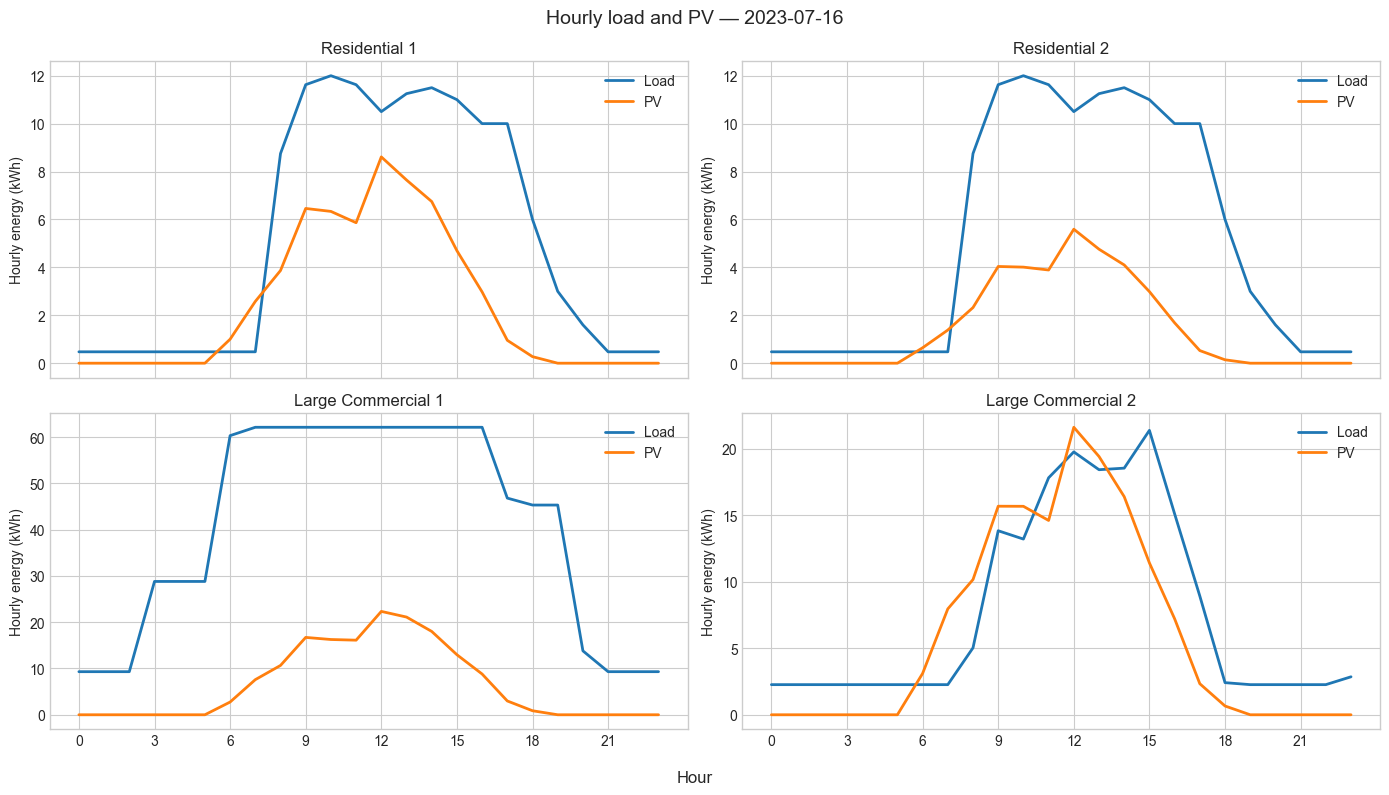

In [5]:
PLOT_DATE = "2023-07-16"
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)

for (building_name, profile), axis in zip(profiles.items(), axes.flat):
    daily = profile.loc[PLOT_DATE]
    hours = daily.index.hour
    axis.plot(hours, daily["load_kwh"], label="Load", linewidth=2)
    axis.plot(hours, daily["pv_kwh"], label="PV", linewidth=2)
    axis.set_title(building_name)
    axis.set_ylabel("Hourly energy (kWh)")
    axis.set_xticks(range(0, 24, 3))
    axis.legend()

fig.supxlabel("Hour")
fig.suptitle(f"Hourly load and PV — {PLOT_DATE}", fontsize=14)
fig.tight_layout()
plt.show()